# Notebook 05 - Full TGVAE (Transformer Graph VAE), end-to-end on EGFR data

This notebook implements the **complete** transformer graph variational autoencoder from Nguyen & Karolak (2025), adapted to your EGFR/NSCLC dataset. Unlike notebook 4 (which swapped only the encoder), this is a different model end-to-end:

- **Encoder** - a graph-attention transformer over the molecular graph (`TransformerConv` with residual + LayerNorm and a dense / jumping-knowledge connection to counter over-smoothing), pooled and projected to a VAE latent.
- **Decoder** - an **autoregressive SMILES transformer** that generates the molecule token by token, cross-attending to the latent and to the **EGFR pocket embedding** (kept from notebooks 1 and 3, so generation stays target-conditioned).
- **Training** - VAE objective (token reconstruction NLL + KL) with a **cyclical beta** schedule and free-bits to combat posterior collapse, the two issues the paper highlights.

It reuses your existing `graph_data.pt` directly - each graph already carries its canonical `SMILES` string (attached in notebook 1), which the decoder needs as its target. Notebooks 1-4 are untouched.

> Reference: Nguyen & Karolak (2025), *Transformer graph variational autoencoder for generative molecular design*, Biophysical Journal, doi:10.1016/j.bpj.2025.01.022. This adaptation adds EGFR pocket conditioning, which the original (MOSES, unconditional) model does not use.

**Note:** this is a full training notebook, written to run in your environment (GPU recommended). It was not executed here.

In [1]:
import os, math, random, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torch_geometric.data import Batch
from torch_geometric.nn import TransformerConv, global_add_pool

import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import QED, Descriptors, AllChem, DataStructs
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

c:\Users\u2251865\.conda\envs\tree4\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


## 1. Data and SMILES tokenizer

Load the graph dataset, canonicalise each molecule's SMILES with RDKit, and tokenize. The tokenizer is regex-free and handles bracketed atoms (e.g. `[nH]`, `[C@@H]`), two-character halogens (`Br`, `Cl`) and two-digit ring closures (`%10`). Special tokens: `<pad> <bos> <eos> <unk>`. Molecules longer than `MAX_LEN` tokens are dropped.

In [2]:
DATA_PATH = '../data/processed/graph_data.pt'
container = torch.load(DATA_PATH, weights_only=False)
graphs = container['graphs']
print(f'Loaded {len(graphs)} graphs')

def tokenize_smiles(s):
    tokens, i, n = [], 0, len(s)
    while i < n:
        c = s[i]
        if c == '[':
            j = s.find(']', i)
            if j == -1:
                tokens.append(c); i += 1
            else:
                tokens.append(s[i:j+1]); i = j + 1
        elif s[i:i+2] in ('Br', 'Cl'):
            tokens.append(s[i:i+2]); i += 2
        elif c == '%' and i + 2 < n and s[i+1:i+3].isdigit():
            tokens.append(s[i:i+3]); i += 3
        else:
            tokens.append(c); i += 1
    return tokens

PAD, BOS, EOS, UNK = '<pad>', '<bos>', '<eos>', '<unk>'
SPECIAL = [PAD, BOS, EOS, UNK]
MAX_LEN = 120                      # max SMILES token length (excl. BOS/EOS)

# pairs: [graph, tokens, canonical_smiles]; kept only if RDKit-valid and short enough
pairs, all_tokens, kept_smiles = [], set(), []
for g in graphs:
    smi = getattr(g, 'SMILES', None)
    if not smi:
        continue
    m = Chem.MolFromSmiles(smi)
    if m is None:
        continue
    can = Chem.MolToSmiles(m)
    toks = tokenize_smiles(can)
    if len(toks) > MAX_LEN:
        continue
    pairs.append([g, toks, can]); all_tokens.update(toks); kept_smiles.append(can)

vocab = SPECIAL + sorted(all_tokens)
stoi = {t: i for i, t in enumerate(vocab)}
itos = {i: t for t, i in stoi.items()}
PAD_ID, BOS_ID, EOS_ID, UNK_ID = (stoi[t] for t in SPECIAL)

def encode(toks):
    return [BOS_ID] + [stoi.get(t, UNK_ID) for t in toks] + [EOS_ID]

for p in pairs:
    p.append(encode(p[1]))          # p = [graph, tokens, canonical_smiles, token_ids]

train_smiles_set = set(kept_smiles)
print(f'Kept {len(pairs)} / {len(graphs)} molecules | vocab {len(vocab)} | max_len {MAX_LEN}')

Loaded 19846 graphs
Kept 19846 / 19846 molecules | vocab 56 | max_len 120


In [3]:
class MolSeqDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, i):
        g, toks, can, ids = self.pairs[i]
        return g, ids

def collate(items):
    graph_list, id_lists = zip(*items)
    gbatch = Batch.from_data_list(list(graph_list))
    gf = torch.stack([g.global_features.view(-1)[:2] for g in graph_list]).float()
    pk = torch.stack([g.pocket_embedding.view(-1) for g in graph_list]).float()
    T = max(len(x) for x in id_lists)
    tok = torch.full((len(id_lists), T), PAD_ID, dtype=torch.long)
    for i, x in enumerate(id_lists):
        tok[i, :len(x)] = torch.tensor(x, dtype=torch.long)
    return gbatch, gf, pk, tok

full_ds = MolSeqDataset(pairs)
n_val = int(0.1 * len(full_ds)); n_train = len(full_ds) - n_val
train_ds, val_ds = random_split(full_ds, [n_train, n_val],
                                generator=torch.Generator().manual_seed(SEED))
BATCH = 64
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  collate_fn=collate)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, collate_fn=collate)
print(f'Train {n_train} | Val {n_val}')

Train 17862 | Val 1984


## 2. Graph-attention encoder

Multi-head attention message passing with per-layer residual + LayerNorm, and a final dense concatenation of all layer outputs (jumping-knowledge) to counter over-smoothing in the deep GNN. `global_add_pool` produces the graph memory, concatenated with two global descriptors and projected to the latent mean and log-variance.

In [4]:
class GraphAttentionEncoder(nn.Module):
    """Graph-attention (transformer) encoder for TGVAE.
    Multi-head attention message passing (TransformerConv) with per-layer
    residual + LayerNorm and a final dense (jumping-knowledge) concatenation of
    all layer outputs to counter over-smoothing. global_add_pool gives the graph
    memory, which (with 2 global descriptors) is projected to the VAE latent."""
    def __init__(self, node_features=8, edge_features=5, global_features=2,
                 d_model=256, heads=8, num_layers=4, latent_dim=64, dropout=0.2):
        super().__init__()
        assert d_model % heads == 0
        self.node_emb = nn.Linear(node_features, d_model)
        self.edge_emb = nn.Linear(edge_features, d_model)
        self.convs = nn.ModuleList([
            TransformerConv(d_model, d_model // heads, heads=heads,
                            edge_dim=d_model, dropout=dropout)
            for _ in range(num_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(num_layers)])
        self.jk = nn.Linear(num_layers * d_model, d_model)   # dense connection
        self.dropout = nn.Dropout(dropout)
        self.to_mu     = nn.Linear(d_model + global_features, latent_dim)
        self.to_logvar = nn.Linear(d_model + global_features, latent_dim)

    def forward(self, x, edge_index, edge_attr, batch, global_features):
        h = F.relu(self.node_emb(x))
        e = F.relu(self.edge_emb(edge_attr))
        outs = []
        for conv, norm in zip(self.convs, self.norms):
            h_new = conv(h, edge_index, e)
            h = norm(h + self.dropout(F.relu(h_new)))        # residual + LayerNorm
            outs.append(h)
        h = self.jk(torch.cat(outs, dim=-1))                 # jumping-knowledge concat
        gemb = global_add_pool(h, batch)                     # [B, d_model]
        gemb = torch.cat([gemb, global_features], dim=-1)
        mu     = torch.clamp(self.to_mu(gemb),     -20.0, 20.0)
        logvar = torch.clamp(self.to_logvar(gemb), -10.0,  4.0)
        return mu, logvar

## 3. Autoregressive SMILES decoder

The latent `z` is expanded into a short memory sequence and concatenated with the projected EGFR pocket embedding; a causal Transformer decoder then emits SMILES tokens autoregressively, cross-attending to that memory. Training uses teacher forcing; generation samples token by token until `<eos>`.

In [5]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))          # [1, max_len, d_model]
    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])

class SmilesTransformerDecoder(nn.Module):
    """Autoregressive SMILES decoder. The latent z (expanded to a short memory)
    and the EGFR pocket embedding form the cross-attention memory; a causal
    Transformer decoder emits SMILES tokens one position at a time."""
    def __init__(self, vocab_size, latent_dim=64, pocket_dim=128, d_model=256,
                 heads=8, num_layers=4, dim_ff=512, mem_len=4, dropout=0.2, pad_id=0):
        super().__init__()
        self.d_model, self.mem_len, self.pad_id = d_model, mem_len, pad_id
        self.tok_emb = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos_enc = PositionalEncoding(d_model, dropout=dropout)
        self.z_to_mem = nn.Linear(latent_dim, mem_len * d_model)
        self.pocket_to_mem = nn.Linear(pocket_dim, d_model)
        layer = nn.TransformerDecoderLayer(d_model, heads, dim_ff, dropout, batch_first=True)
        self.decoder = nn.TransformerDecoder(layer, num_layers)
        self.out = nn.Linear(d_model, vocab_size)

    def make_memory(self, z, pocket):
        B = z.size(0)
        m = self.z_to_mem(z).view(B, self.mem_len, self.d_model)
        p = self.pocket_to_mem(pocket).unsqueeze(1)          # [B, 1, d_model]
        return torch.cat([m, p], dim=1)                      # [B, mem_len+1, d_model]

    def forward(self, z, pocket, tgt_in):
        mem = self.make_memory(z, pocket)
        t = self.pos_enc(self.tok_emb(tgt_in))
        T = tgt_in.size(1)
        causal = torch.triu(torch.full((T, T), float('-inf'), device=tgt_in.device), diagonal=1)
        pad_mask = (tgt_in == self.pad_id)
        h = self.decoder(t, mem, tgt_mask=causal, tgt_key_padding_mask=pad_mask)
        return self.out(h)

In [6]:
class TGVAE(nn.Module):
    def __init__(self, vocab_size, cfg):
        super().__init__()
        self.encoder = GraphAttentionEncoder(
            node_features=cfg['node_features'], edge_features=cfg['edge_features'],
            global_features=cfg['global_features'], d_model=cfg['d_model'],
            heads=cfg['heads'], num_layers=cfg['enc_layers'],
            latent_dim=cfg['latent_dim'], dropout=cfg['dropout'])
        self.decoder = SmilesTransformerDecoder(
            vocab_size, latent_dim=cfg['latent_dim'], pocket_dim=cfg['pocket_dim'],
            d_model=cfg['d_model'], heads=cfg['heads'], num_layers=cfg['dec_layers'],
            dim_ff=cfg['dim_ff'], mem_len=cfg['mem_len'], dropout=cfg['dropout'],
            pad_id=cfg['pad_id'])
        self.latent_dim = cfg['latent_dim']
        self.pad_id = cfg['pad_id']
        self.free_bits = cfg.get('free_bits', 0.0)

    def reparameterize(self, mu, logvar):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)

    def forward(self, gbatch, gf, pk, tok, beta=1.0):
        mu, logvar = self.encoder(gbatch.x, gbatch.edge_index, gbatch.edge_attr,
                                  gbatch.batch, gf)
        z = self.reparameterize(mu, logvar)
        tgt_in, tgt_out = tok[:, :-1], tok[:, 1:]
        logits = self.decoder(z, pk, tgt_in)
        B, V = tok.size(0), logits.size(-1)
        recon = F.cross_entropy(logits.reshape(-1, V), tgt_out.reshape(-1),
                                ignore_index=self.pad_id, reduction='sum') / B
        kl_dim = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp())      # [B, latent]
        if self.free_bits > 0:
            kl_dim = torch.clamp(kl_dim, min=self.free_bits)
        kl = kl_dim.sum(dim=1).mean()
        loss = recon + beta * kl
        return loss, recon, kl

    @torch.no_grad()
    def generate(self, pocket, max_len=120, temperature=1.0, z=None,
                 bos_id=1, eos_id=2):
        self.eval()
        n = pocket.size(0)
        if z is None:
            z = torch.randn(n, self.latent_dim, device=pocket.device)
        mem = self.decoder.make_memory(z, pocket)
        seqs = torch.full((n, 1), bos_id, dtype=torch.long, device=pocket.device)
        done = torch.zeros(n, dtype=torch.bool, device=pocket.device)
        for _ in range(max_len):
            t = self.decoder.pos_enc(self.decoder.tok_emb(seqs))
            T = seqs.size(1)
            causal = torch.triu(torch.full((T, T), float('-inf'), device=pocket.device), diagonal=1)
            h = self.decoder.decoder(t, mem, tgt_mask=causal)
            logits = self.decoder.out(h[:, -1]) / max(temperature, 1e-6)
            nxt = torch.multinomial(F.softmax(logits, dim=-1), 1).squeeze(1)
            nxt = torch.where(done, torch.full_like(nxt, eos_id), nxt)
            seqs = torch.cat([seqs, nxt.unsqueeze(1)], dim=1)
            done = done | (nxt == eos_id)
            if done.all():
                break
        return seqs

## 4. Train the TGVAE

VAE loss = per-sequence token NLL + beta * KL, with a cyclical beta schedule (4 cycles) and free-bits (0.2 nats/dim) to prevent posterior collapse. Adam + cosine LR, gradient clipping. Reduce `EPOCHS`, `d_model`, or subset `pairs` for a quick smoke test.

In [7]:
cfg = {
    'node_features': 8, 'edge_features': 5, 'global_features': 2,
    'pocket_dim': 128, 'latent_dim': 64,
    'd_model': 256, 'heads': 8, 'enc_layers': 4, 'dec_layers': 4,
    'dim_ff': 512, 'mem_len': 4, 'dropout': 0.2,
    'pad_id': PAD_ID, 'free_bits': 0.2,
}
model = TGVAE(len(vocab), cfg).to(device)
print(f'TGVAE parameters: {sum(p.numel() for p in model.parameters()):,}')

EPOCHS, BETA_MAX, N_CYCLES = 60, 0.3, 4
def cyclical_beta(epoch, epochs=EPOCHS, n_cycles=N_CYCLES, beta_max=BETA_MAX, ratio=0.5):
    period = epochs / n_cycles
    pos = (epoch % period) / period
    return beta_max * min(1.0, pos / ratio)     # linear warm-up then hold, per cycle

opt = torch.optim.Adam(model.parameters(), lr=3e-4, weight_decay=1e-6)
sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-6)
CLIP = 1.0

def run_epoch(loader, train, beta):
    model.train() if train else model.eval()
    tot = {'loss': 0.0, 'recon': 0.0, 'kl': 0.0}; nb = 0
    torch.set_grad_enabled(train)
    for gbatch, gf, pk, tok in loader:
        gbatch = gbatch.to(device); gf = gf.to(device); pk = pk.to(device); tok = tok.to(device)
        loss, recon, kl = model(gbatch, gf, pk, tok, beta=beta)
        if train:
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP); opt.step()
        tot['loss'] += loss.item(); tot['recon'] += recon.item(); tot['kl'] += kl.item(); nb += 1
    torch.set_grad_enabled(True)
    return {k: v / max(nb, 1) for k, v in tot.items()}

hist = {'train': {'loss': [], 'recon': [], 'kl': []},
        'val':   {'loss': [], 'recon': [], 'kl': []}, 'beta': []}
for epoch in range(EPOCHS):
    beta = cyclical_beta(epoch)
    tr = run_epoch(train_loader, True,  beta)
    va = run_epoch(val_loader,   False, beta)
    sch.step()
    for k in ('loss', 'recon', 'kl'):
        hist['train'][k].append(tr[k]); hist['val'][k].append(va[k])
    hist['beta'].append(beta)
    if epoch % 5 == 0 or epoch == EPOCHS - 1:
        print(f"Epoch {epoch:3d} | beta {beta:.3f} | train recon {tr['recon']:.3f} kl {tr['kl']:.3f} | val recon {va['recon']:.3f} kl {va['kl']:.3f}")

os.makedirs('../models', exist_ok=True)
torch.save({'model': model.state_dict(), 'vocab': vocab, 'cfg': cfg}, '../models/tgvae_egfr.pth')
print('Saved -> ../models/tgvae_egfr.pth')

TGVAE parameters: 4,907,704


c:\Users\u2251865\.conda\envs\tree4\Lib\site-packages\torch\nn\modules\activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


Epoch   0 | beta 0.000 | train recon 121.505 kl 12585.518 | val recon 110.798 kl 12943.626
Epoch   5 | beta 0.200 | train recon 53.572 kl 99.992 | val recon 44.112 kl 107.244
Epoch  10 | beta 0.300 | train recon 40.506 kl 93.104 | val recon 31.843 kl 95.107
Epoch  15 | beta 0.000 | train recon 31.047 kl 231.296 | val recon 22.834 kl 286.613
Epoch  20 | beta 0.200 | train recon 27.185 kl 99.515 | val recon 20.968 kl 104.706
Epoch  25 | beta 0.300 | train recon 25.564 kl 95.704 | val recon 19.025 kl 97.027
Epoch  30 | beta 0.000 | train recon 20.540 kl 210.266 | val recon 14.170 kl 250.978
Epoch  35 | beta 0.200 | train recon 20.433 kl 100.882 | val recon 15.014 kl 103.743
Epoch  40 | beta 0.300 | train recon 20.210 kl 96.818 | val recon 14.840 kl 98.711
Epoch  45 | beta 0.000 | train recon 16.506 kl 193.800 | val recon 11.576 kl 236.305
Epoch  50 | beta 0.200 | train recon 17.792 kl 101.302 | val recon 13.176 kl 103.186
Epoch  55 | beta 0.300 | train recon 18.326 kl 97.354 | val recon 1

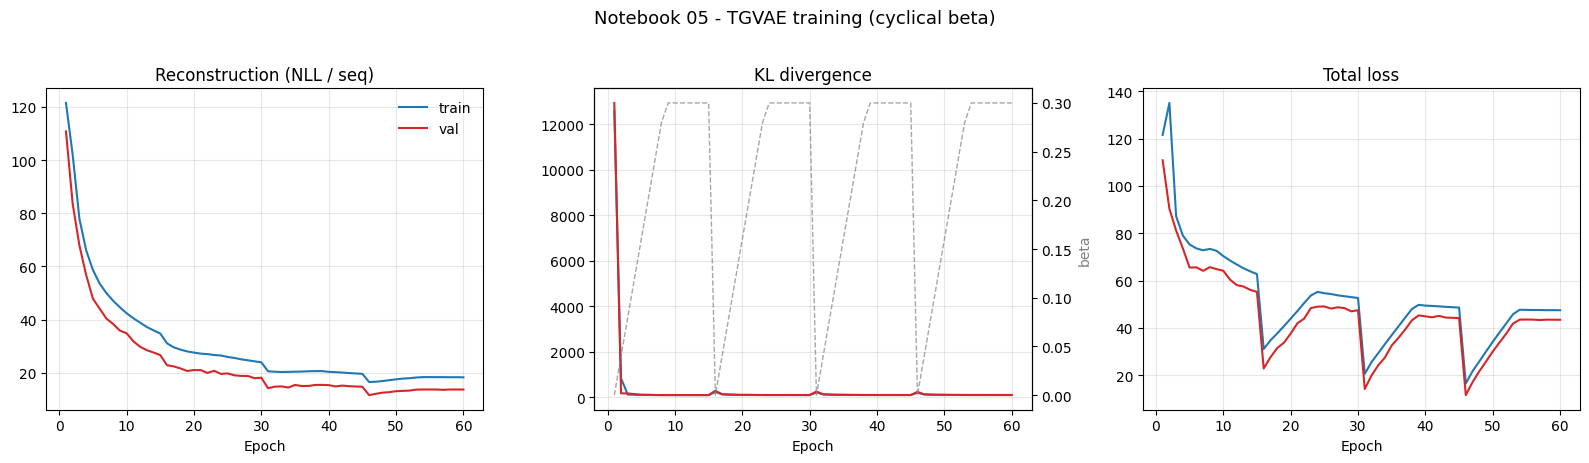

In [8]:
ep = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, k, title in zip(axes, ['recon', 'kl', 'loss'],
                        ['Reconstruction (NLL / seq)', 'KL divergence', 'Total loss']):
    ax.plot(ep, hist['train'][k], label='train', color='#1f77b4')
    ax.plot(ep, hist['val'][k],   label='val',   color='#d62728')
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.grid(alpha=0.3)
axes[0].legend(frameon=False)
ax2 = axes[1].twinx(); ax2.plot(ep, hist['beta'], color='gray', ls='--', lw=1, alpha=0.7)
ax2.set_ylabel('beta', color='gray')
fig.suptitle('Notebook 05 - TGVAE training (cyclical beta)', y=1.02, fontsize=13)
fig.tight_layout()
os.makedirs('../results/figures', exist_ok=True)
fig.savefig('../results/figures/nb05_tgvae_training.png', dpi=300, bbox_inches='tight')
plt.show()

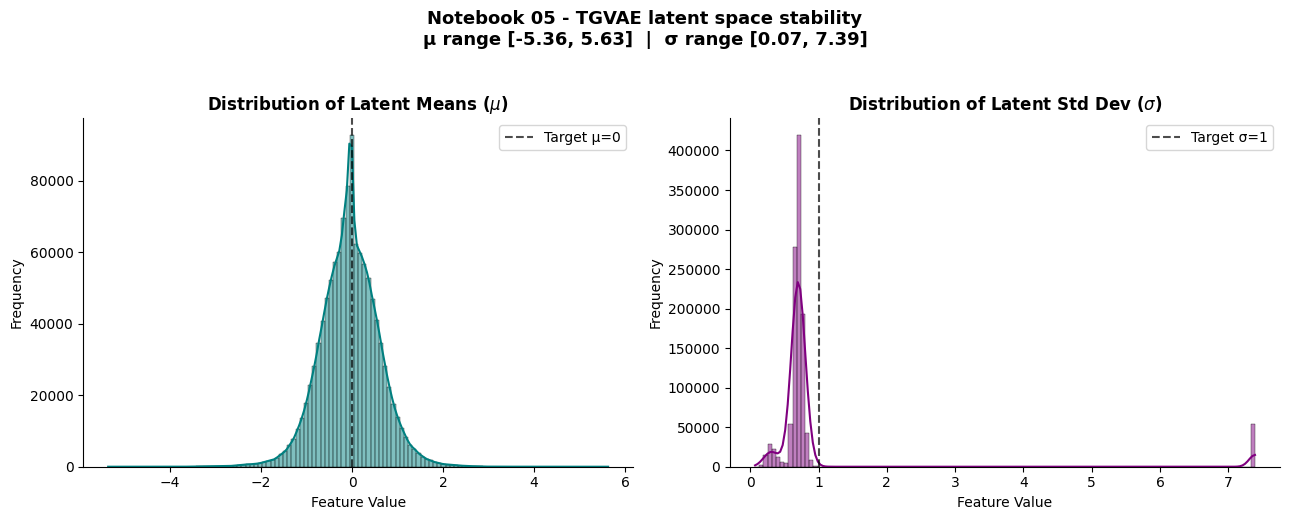

Saved: ../results/figures/nb05_tgvae_latent_distribution.png


In [16]:
# --- Latent posterior diagnostics (Notebook 3-style figure) ---
@torch.no_grad()
def extract_latent_stats(loader):
    model.eval()
    mu_list, std_list = [], []
    for gbatch, gf, pk, tok in loader:
        gbatch = gbatch.to(device)
        gf = gf.to(device)
        pk = pk.to(device)
        if gf.dim() == 1:
            gf = gf.view(gbatch.num_graphs, -1)
        if pk.dim() == 1:
            pk = pk.view(gbatch.num_graphs, -1)
        mu, logvar = model.encoder(gbatch.x, gbatch.edge_index, gbatch.edge_attr,
                                   gbatch.batch, gf)
        std = torch.exp(0.5 * logvar)
        mu_list.append(mu.cpu().numpy())
        std_list.append(std.cpu().numpy())
    mu_array = np.concatenate(mu_list, axis=0)
    std_array = np.concatenate(std_list, axis=0)
    return mu_array, std_array

mu_matrix, std_matrix = extract_latent_stats(train_loader)
mu_flat = mu_matrix.flatten()
std_flat = std_matrix.flatten()

import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(mu_flat, bins=120, kde=True, color='teal', ax=ax1)
ax1.set_title(r'Distribution of Latent Means ($\mu$)', fontweight='bold')
ax1.set_xlabel('Feature Value')
ax1.set_ylabel('Frequency')
ax1.axvline(0, color='black', linestyle='--', alpha=0.7, label='Target μ=0')
ax1.legend()

sns.histplot(std_flat, bins=120, kde=True, color='purple', ax=ax2)
ax2.set_title(r'Distribution of Latent Std Dev ($\sigma$)', fontweight='bold')
ax2.set_xlabel('Feature Value')
ax2.set_ylabel('Frequency')
ax2.axvline(1, color='black', linestyle='--', alpha=0.7, label='Target σ=1')
ax2.legend()

plt.suptitle(
    f'Notebook 05 - TGVAE latent space stability\n'
    f'μ range [{mu_flat.min():.2f}, {mu_flat.max():.2f}]  |  '
    f'σ range [{std_flat.min():.2f}, {std_flat.max():.2f}]',
    fontsize=13, fontweight='bold', y=1.03
)
sns.despine()
plt.tight_layout()
os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/nb05_tgvae_latent_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: ../results/figures/nb05_tgvae_latent_distribution.png')

## 5. Generate and evaluate

Sample latents from the prior, condition on the mean EGFR pocket, and decode autoregressively. Report validity, uniqueness, novelty (vs the training set), internal diversity (mean pairwise Tanimoto distance) and mean QED, matching the paper's metrics, then plot property distributions.

In [9]:
def ids_to_smiles(seq):
    out = []
    for i in seq.tolist():
        t = itos.get(i, '')
        if t == EOS:
            break
        if t in (BOS, PAD):
            continue
        out.append(t)
    return ''.join(out)

# Representative EGFR pocket = mean pocket embedding across the dataset
mean_pocket = torch.stack([g.pocket_embedding.view(-1) for g, *_ in pairs]).float().mean(0)

@torch.no_grad()
def sample(n=3000, batch=256, temperature=1.0):
    out = []
    for s in range(0, n, batch):
        b = min(batch, n - s)
        pk = mean_pocket.unsqueeze(0).repeat(b, 1).to(device)
        seqs = model.generate(pk, max_len=MAX_LEN, temperature=temperature,
                              bos_id=BOS_ID, eos_id=EOS_ID)
        out.extend(ids_to_smiles(seq) for seq in seqs)
    return out

def int_diversity(mols, sample_n=500):
    if len(mols) > sample_n:
        mols = random.Random(SEED).sample(mols, sample_n)
    fps = [AllChem.GetMorganFingerprintAsBitVect(m, 2, 1024) for m in mols]
    sims = []
    for i in range(len(fps)):
        sims.extend(DataStructs.BulkTanimotoSimilarity(fps[i], fps[i+1:]))
    return float(1 - np.mean(sims)) if sims else float('nan')

raw = sample(3000, temperature=1.0)
valid = [(s, Chem.MolFromSmiles(s)) for s in raw if s]
valid = [(s, m) for s, m in valid if m is not None]
canon = [Chem.MolToSmiles(m) for _, m in valid]
uniq = set(canon)
novel = uniq - train_smiles_set
metrics = {
    'sampled': len(raw),
    'validity': len(valid) / len(raw),
    'uniqueness': len(uniq) / max(len(valid), 1),
    'novelty': len(novel) / max(len(uniq), 1),
    'int_diversity': int_diversity([m for _, m in valid]),
    'mean_QED': float(np.mean([QED.qed(m) for _, m in valid])) if valid else float('nan'),
}
pd.DataFrame([metrics]).to_csv('../results/nb05_tgvae_metrics.csv', index=False)
print(json.dumps(metrics, indent=2))

{
  "sampled": 3000,
  "validity": 0.389,
  "uniqueness": 0.9708654670094259,
  "novelty": 0.9302736098852604,
  "int_diversity": 0.8034897864865329,
  "mean_QED": 0.4928768276774145
}


T=0.5 | valid 0.612 | uniq 0.900 | novel 0.866 | div 0.786 | QED 0.485
T=0.6 | valid 0.587 | uniq 0.925 | novel 0.877 | div 0.788 | QED 0.474
T=0.7 | valid 0.519 | uniq 0.941 | novel 0.888 | div 0.788 | QED 0.483
T=0.8 | valid 0.492 | uniq 0.967 | novel 0.884 | div 0.794 | QED 0.494
T=0.9 | valid 0.453 | uniq 0.965 | novel 0.916 | div 0.788 | QED 0.490
T=1.0 | valid 0.397 | uniq 0.982 | novel 0.890 | div 0.797 | QED 0.506


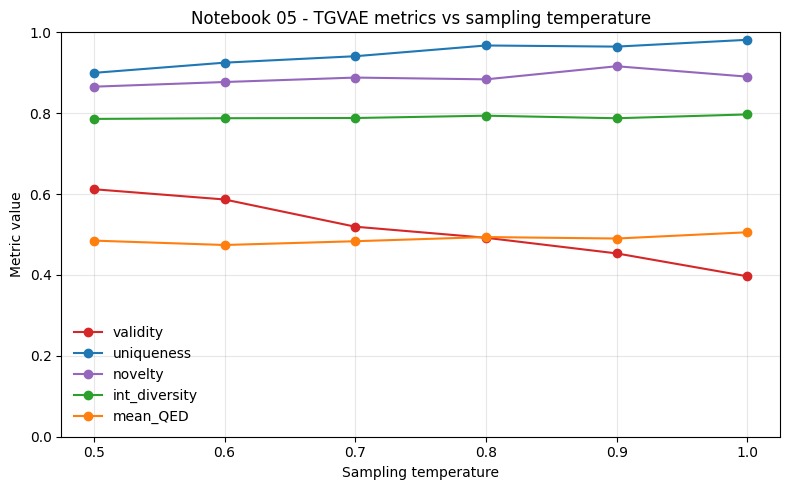


Highest validity at T=0.5: 0.612 (QED 0.485, diversity 0.786)


In [19]:
# --- Temperature sweep: lift validity without retraining ---
# Reuses: model, sample(), int_diversity, train_smiles_set, Chem, QED, np, pd, plt

def eval_generated(smiles, n_sampled):
    parsed = [(s, Chem.MolFromSmiles(s)) for s in smiles if s]
    valid_ = [(s, m) for s, m in parsed if m is not None]
    canon_ = [Chem.MolToSmiles(m) for _, m in valid_]
    uniq_  = set(canon_)
    novel_ = uniq_ - train_smiles_set
    return {
        'validity'     : len(valid_) / n_sampled,
        'uniqueness'   : len(uniq_) / max(len(valid_), 1),
        'novelty'      : len(novel_) / max(len(uniq_), 1),
        'int_diversity': int_diversity([m for _, m in valid_]),
        'mean_QED'     : float(np.mean([QED.qed(m) for _, m in valid_])) if valid_ else float('nan'),
    }

N_SWEEP = 1500
TEMPS   = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
rows = []
for T in TEMPS:
    smi = sample(N_SWEEP, temperature=T)
    row = {'temperature': T, **eval_generated(smi, N_SWEEP)}
    rows.append(row)
    print(f"T={T:.1f} | valid {row['validity']:.3f} | uniq {row['uniqueness']:.3f} | "
          f"novel {row['novelty']:.3f} | div {row['int_diversity']:.3f} | QED {row['mean_QED']:.3f}")

sweep = pd.DataFrame(rows)
sweep.to_csv('../results/nb05_temperature_sweep.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 5))
for col, c in [('validity', '#d62728'), ('uniqueness', '#1f77b4'),
               ('novelty', '#9467bd'), ('int_diversity', '#2ca02c'), ('mean_QED', '#ff7f0e')]:
    ax.plot(sweep['temperature'], sweep[col], marker='o', label=col, color=c)
ax.set_xlabel('Sampling temperature'); ax.set_ylabel('Metric value'); ax.set_ylim(0, 1)
ax.set_title('Notebook 05 - TGVAE metrics vs sampling temperature')
ax.grid(alpha=0.3); ax.legend(frameon=False)
fig.tight_layout()
fig.savefig('../results/figures/nb05_temperature_sweep.png', dpi=300, bbox_inches='tight')
plt.show()

best = sweep.loc[sweep['validity'].idxmax()]
print(f"\nHighest validity at T={best['temperature']:.1f}: {best['validity']:.3f} "
      f"(QED {best['mean_QED']:.3f}, diversity {best['int_diversity']:.3f})")

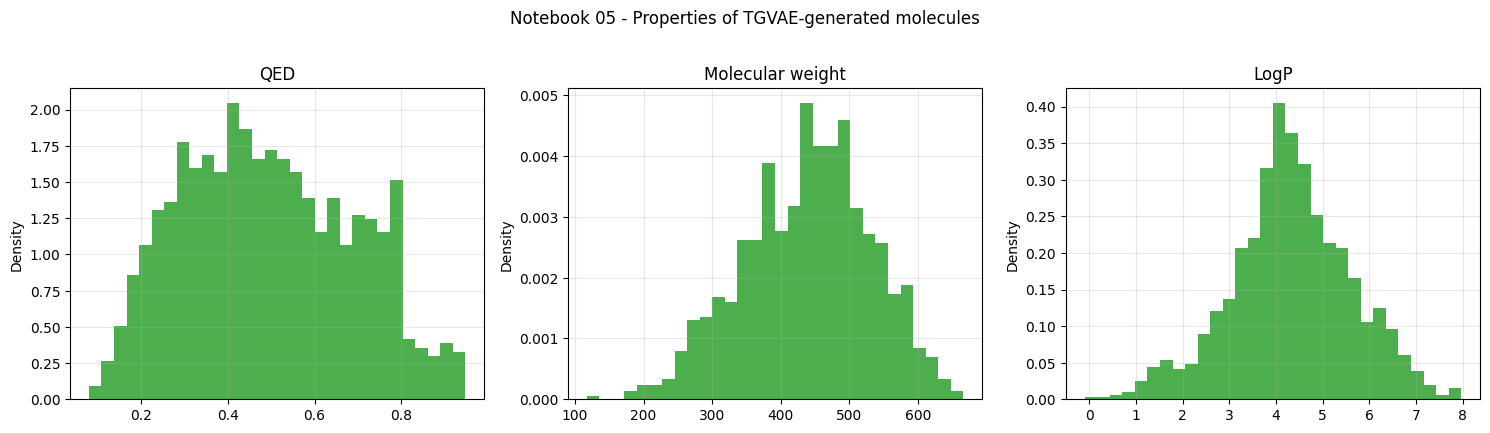

Example novel SMILES:
   COc1cc2ncnc(-c3cn(C)nc3-c3ccccc3)c2cc1NC(=O)/C=C/CN(C)C
   CC(C)(C)COc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1NC(=O)CCCn1ccnc1
   O=C(Nc1ncnc2sc(-c3ccc(CO)cc3)cc12)c1ccccc1
   COc1ccc(C=CNc2cccc(Br)c2)cc1
   C=CC(=O)Nc1cc2c(cc1OC)=CC=2NC1=CC=C(NC(=O)Nc2cccc(Br)c2)N=CN=C1
   CN1CCC[C@H]1CN1CC(c2ccc(Oc3cccc(Cl)c3F)c3c(N)ncnc23)=N1
   COc1ccncc1-c1cc2c(cnn2-c2cc3c(F)cc(N4CCOCC4)c-3nc(NC3CCC3)n2)c(C)n1
   C=CC(=O)Nc1cc(Nc2ncc(Cl)c(-c3cnn4ccccc34)n2)c(OC)cc1N1CCC(N(C)CC)C1
   COc1cc(N2N=C2C(=O)/N=c2\[nH]c3ccccc3n2[C@H]2C[C@@H](C)C2)c(OC)cc1N(C)C
   O=C1CSC(N2N=C(c3ccc(O)cc3)CC2c2ccccc2)C1
   COc1cccc(-c2cc3c(Nc4ccc(OCC(F)(F)F)cc4)ncnc3s2)c1
   CCN(C/C=C/c1nc2c(s1)=NC=NC(Nc1ccc(F)c(Cl)c1)=CC=2Cl)C(C)C
   COc1ccncc1-c1cc2n(-c3ccccc3)nc-2c(C2CCN(C(C)=O)CC2)cc1N
   COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1N1C[C@@H]2C(=O)N1CCOCCCN2C
   O=C(O)Cc1ccc(S(=O)(=O)Nc2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c(Cl)c4)c3c2)cc1


In [10]:
vmols = [m for _, m in valid]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, fn, title in zip(axes,
        [QED.qed, Descriptors.MolWt, Descriptors.MolLogP],
        ['QED', 'Molecular weight', 'LogP']):
    ax.hist([fn(m) for m in vmols], bins=30, color='#2ca02c', alpha=0.85, density=True)
    ax.set_title(title); ax.set_ylabel('Density'); ax.grid(alpha=0.3)
fig.suptitle('Notebook 05 - Properties of TGVAE-generated molecules', y=1.02)
fig.tight_layout()
fig.savefig('../results/figures/nb05_tgvae_properties.png', dpi=300, bbox_inches='tight')
plt.show()

examples = [s for s in canon if s in novel][:15]
print('Example novel SMILES:')
for s in examples:
    print('  ', s)

In [12]:
# --- Rank top EGFR-viable candidates for docking (full profile, incl. SA score) ---
import os, sys, importlib
from rdkit.Chem import Crippen, rdMolDescriptors

GEN_TEMPERATURE = 0.7      # operating point from the temperature sweep
POOL_SIZE       = 5000     # generate a large pool, then filter down
TOP_K           = 20       # candidates to export for docking

def sa_score(mol):
    """Synthetic accessibility (1 easy .. 10 hard). RDKit sascorer if available,
    else a ring-density fallback - same logic as notebook 3."""
    try:
        from rdkit.Chem import RDConfig
        sys.path.append(os.path.join(RDConfig.RDContribDir, 'SA_Score'))
        sascorer = importlib.import_module('sascorer')
        return sascorer.calculateScore(mol)
    except Exception:
        n = mol.GetNumAtoms()
        if n == 0: return 10.0
        return max(1.0, min(10.0, 1.0 + 9.0 * rdMolDescriptors.CalcNumRings(mol) / n))

def evaluate_molecule(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None: return None
    mw, logp = Descriptors.MolWt(mol), Crippen.MolLogP(mol)
    hbd, hba = Descriptors.NumHDonors(mol), Descriptors.NumHAcceptors(mol)
    return {
        'SMILES': smiles, 'QED': round(QED.qed(mol), 4),
        'SA_score': round(sa_score(mol), 3), 'MW': round(mw, 2), 'LogP': round(logp, 3),
        'HBD': hbd, 'HBA': hba,
        'Lipinski_pass': int(mw < 500 and logp < 5 and hbd < 5 and hba < 10),
        'Aromatic_rings': rdMolDescriptors.CalcNumAromaticRings(mol),
        'NumAtoms': mol.GetNumHeavyAtoms(),
    }

def is_egfr_viable(mol):
    if mol is None: return False
    if rdMolDescriptors.CalcNumAromaticRings(mol) < 1: return False
    ha = mol.GetNumHeavyAtoms()
    if ha < 15 or ha > 55: return False
    if sum(a.GetAtomicNum() == 9 for a in mol.GetAtoms()) > 6: return False
    if Descriptors.MolWt(mol) > 600: return False
    return True

pool = sample(POOL_SIZE, temperature=GEN_TEMPERATURE)

seen, rows = set(), []
for s in pool:
    mol = Chem.MolFromSmiles(s) if s else None
    if mol is None or not is_egfr_viable(mol):
        continue
    can = Chem.MolToSmiles(mol)
    if can in seen or can in train_smiles_set:     # unique + novel
        continue
    seen.add(can)
    prof = evaluate_molecule(can)
    if prof: rows.append(prof)

cand = pd.DataFrame(rows).sort_values('QED', ascending=False).reset_index(drop=True)
cand.insert(0, 'candidate_id', [f'TGVAE-Lead-{i+1:02d}' for i in range(len(cand))])

top = cand.head(TOP_K)
os.makedirs('../results/generated_mols', exist_ok=True)
top.to_csv('../results/generated_mols/tgvae_top_candidates.csv', index=False)
print(f'Pool {POOL_SIZE} -> {len(cand)} viable/novel/unique -> top {len(top)} saved (ranked by QED)')
print('Saved -> ../results/generated_mols/tgvae_top_candidates.csv')
top[['candidate_id','SMILES','QED','SA_score','MW','LogP','HBD','HBA','Lipinski_pass','Aromatic_rings','NumAtoms']]

Pool 5000 -> 1989 viable/novel/unique -> top 20 saved (ranked by QED)
Saved -> ../results/generated_mols/tgvae_top_candidates.csv


,candidate_id,SMILES,QED,SA_score,MW,LogP,HBD,HBA,Lipinski_pass,Aromatic_rings,NumAtoms
0,TGVAE-Lead-01,Cc1ccc(C(=O)NS(=O)(=O)c2ccc(Cl)cc2)cc1,0.9479,1.599,309.77,2.767,1,3,1,2,20
1,TGVAE-Lead-02,COc1ccc(C2=NN(C(N)=O)C(c3ccccc3)C2)cc1,0.9456,2.503,295.34,2.925,1,3,1,2,22
2,TGVAE-Lead-03,O=C(Nc1ccccn1)C(c1ccc(F)cc1)N1CCCC1,0.9437,2.417,299.35,2.996,1,3,1,2,22
3,TGVAE-Lead-04,CC(C)(O)CN1/C(=N/C(=O)c2cccnc2)c2ccccc21,0.9430,2.699,295.34,2.260,1,3,1,2,22
4,TGVAE-Lead-05,COc1ccc(C2CC(c3ccc(S(N)(=O)=O)cc3)C2)cc1,0.9421,1.926,317.41,3.004,1,3,1,2,22
5,TGVAE-Lead-06,Cc1cccc(C(=O)Nc2ccc(CN3CCN(C)CC3)cc2)n1,0.9380,1.873,324.43,2.390,1,4,1,2,24
6,TGVAE-Lead-07,COc1ccccc1C(=O)NCc1ccc(Br)cc1,0.9377,1.486,320.19,3.388,1,2,1,2,19
7,TGVAE-Lead-08,COc1cc2ncnc(NC3=CC(=O)CCC3)c2cc1OC,0.9354,2.498,299.33,2.696,1,6,1,2,22
8,TGVAE-Lead-09,COc1ccc(-c2csc(N3CC[C@H](O)C3)n2)cc1,0.9347,2.477,276.36,2.390,1,5,1,2,19
9,TGVAE-Lead-10,Cc1ccc(C(=O)NS(=O)(=O)c2ccccc2)cc1,0.9328,1.528,275.33,2.114,1,3,1,2,19


In [13]:
# --- Predicted pIC50 for the shortlist (reuses NB02 regressor + NB01 featurisation) ---
import sys
from pathlib import Path
from rdkit.Chem import (Crippen, Lipinski, rdMolDescriptors, rdDistGeom, rdPartialCharges)
from torch_geometric.data import Data, Batch

# make src/core importable, load the trained regressor with the CHECKPOINT's config
_src = next((c for c in (Path.cwd(), Path.cwd()/'src', Path.cwd().parent/'src')
             if (c/'core'/'gnn_architecture.py').exists()), None)
if _src and str(_src) not in sys.path:
    sys.path.insert(0, str(_src))
from core.gnn_architecture import EGFR_GNN_Regressor

reg = EGFR_GNN_Regressor(node_features=8, edge_features=5, global_features=20,
                         hidden_dim=64, num_layers=2, dropout_rate=0.3,
                         fingerprint_dim=1024, pocket_dim=128).to(device)
reg.load_state_dict(torch.load('../models/best_gnn_regressor.pth', map_location=device))
reg.eval()

def smiles_to_graph(smiles, embed_seed=42):                      # verbatim from NB01
    mol = Chem.MolFromSmiles(smiles)
    if mol is None: return None
    mol_h = Chem.AddHs(Chem.Mol(mol))
    try:
        params = rdDistGeom.ETKDGv3(); params.randomSeed = int(embed_seed); params.useRandomCoords = False
        if AllChem.EmbedMolecule(mol_h, params) != 0:
            AllChem.EmbedMolecule(mol_h, randomSeed=int(embed_seed))
    except Exception: pass
    try: rdPartialCharges.ComputeGasteigerCharges(mol_h)
    except Exception: pass
    conf = mol_h.GetConformer() if mol_h.GetNumConformers() > 0 else None
    coords = []
    for i in range(mol.GetNumAtoms()):
        if conf is not None:
            p = conf.GetAtomPosition(i); coords.append([p.x, p.y, p.z])
        else: coords.append([0.0, 0.0, 0.0])
    coords = np.asarray(coords, dtype=np.float32)
    def atom_feat(idx):
        a = mol.GetAtomWithIdx(idx); ch = 0.0
        try:
            ah = mol_h.GetAtomWithIdx(idx)
            if ah.HasProp('_GasteigerCharge'):
                v = float(ah.GetProp('_GasteigerCharge'))
                if np.isfinite(v): ch = v
        except Exception: ch = 0.0
        return [float(a.GetAtomicNum()), float(a.GetTotalDegree()), float(a.GetFormalCharge()),
                float(int(a.GetHybridization())), float(a.GetIsAromatic()), float(a.GetMass()),
                float(int(a.GetChiralTag())), float(ch)]
    x = [atom_feat(i) for i in range(mol.GetNumAtoms())]
    edge_list, edge_attr = [], []
    for b in mol.GetBonds():
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx(); edge_list += [[i, j], [j, i]]
        bt = b.GetBondType()
        attr = [int(bt == Chem.rdchem.BondType.SINGLE), int(bt == Chem.rdchem.BondType.DOUBLE),
                int(bt == Chem.rdchem.BondType.TRIPLE), int(bt == Chem.rdchem.BondType.AROMATIC),
                int(b.GetStereo() != Chem.rdchem.BondStereo.STEREONONE)]
        edge_attr += [attr, attr]
    if not edge_list:
        edge_index = torch.empty((2, 0), dtype=torch.long); edge_attr_t = torch.empty((0, 5))
    else:
        edge_index = torch.tensor(edge_list, dtype=torch.long).t().contiguous()
        edge_attr_t = torch.tensor(edge_attr, dtype=torch.float32)
    try:
        fp = AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=1024)
        fp_arr = np.array(list(fp.ToBitString()), dtype=np.int8).astype(np.float32)
    except Exception: fp_arr = np.zeros(1024, dtype=np.float32)
    d = Data(x=torch.tensor(x, dtype=torch.float32), edge_index=edge_index,
             edge_attr=edge_attr_t, pos=torch.tensor(coords, dtype=torch.float32))
    d.fingerprint = torch.tensor(fp_arr, dtype=torch.float32)
    return d

def compute_v1_feature_pack(mol, coords_heavy):                  # verbatim from NB01
    eps = 1e-8
    try: rdPartialCharges.ComputeGasteigerCharges(mol)
    except Exception: pass
    charges = []
    for a in mol.GetAtoms():
        try:
            if a.HasProp('_GasteigerCharge'):
                v = float(a.GetProp('_GasteigerCharge'))
                if np.isfinite(v): charges.append(v)
        except Exception: continue
    charges = np.array(charges, dtype=np.float32) if charges else np.zeros(1, dtype=np.float32)
    if coords_heavy is not None and coords_heavy.shape[0] >= 3 and np.any(coords_heavy != 0):
        c = coords_heavy - coords_heavy.mean(axis=0, keepdims=True)
        rg = float(np.sqrt(np.mean(np.sum(c**2, axis=1))))
        eig = np.sort(np.maximum(np.linalg.eigvalsh(np.cov(c.T)), 0.0))[::-1]
        l1, l2, l3 = float(eig[0]), float(eig[1]), float(eig[2])
        asph = float(((l1-l2)**2 + (l2-l3)**2 + (l3-l1)**2) / (2.0*(l1+l2+l3)**2 + eps))
        npr1, npr2 = float(l3/(l1+eps)), float(l2/(l1+eps))
    else: rg, asph, npr1, npr2 = 0.0, 0.0, 0.0, 0.0
    arom = sum(int(a.GetIsAromatic()) for a in mol.GetAtoms())
    het = sum(int(a.GetAtomicNum() not in (1, 6)) for a in mol.GetAtoms())
    feats = [float(Descriptors.MolWt(mol)), float(Crippen.MolLogP(mol)), float(Descriptors.TPSA(mol)),
             float(Descriptors.NumHDonors(mol)), float(Descriptors.NumHAcceptors(mol)),
             float(Descriptors.NumRotatableBonds(mol)), float(rdMolDescriptors.CalcNumRings(mol)),
             float(Lipinski.FractionCSP3(mol)), float(mol.GetNumHeavyAtoms()), float(het),
             float(het/max(1, mol.GetNumAtoms())), float(arom/max(1, mol.GetNumAtoms())),
             float(sum(a.GetFormalCharge() for a in mol.GetAtoms())),
             float(Descriptors.NumValenceElectrons(mol)), float(np.mean(charges)), float(np.std(charges)),
             rg, asph, npr1, npr2]
    arr = np.array(feats, dtype=np.float32)[:20]
    if arr.size < 20: arr = np.pad(arr, (0, 20-arr.size), 'constant')
    return arr

def _featurise(smiles, pocket_vec):
    d = smiles_to_graph(smiles)
    if d is None: return None
    d.global_features = torch.tensor(compute_v1_feature_pack(Chem.MolFromSmiles(smiles),
                                     d.pos.cpu().numpy()), dtype=torch.float32)
    d.pocket_embedding = pocket_vec.detach().clone().float()
    return d

@torch.no_grad()
def predict_pic50(items, y_mean, y_std, bs=128):
    # items: list of (smiles, pocket_vec)
    reg.eval()
    preds = np.full(len(items), np.nan, dtype=np.float32)
    keep, datas = [], []
    for k, (s, pv) in enumerate(items):
        d = _featurise(s, pv)
        if d is not None and d.edge_index.shape[1] > 0:
            keep.append(k); datas.append(d)
    for st in range(0, len(datas), bs):
        gb = Batch.from_data_list(datas[st:st+bs]).to(device)
        out = reg(gb.x, gb.edge_index, gb.batch, edge_attr=gb.edge_attr,
                  global_features=gb.global_features, pos=gb.pos,
                  fingerprint=gb.fingerprint, pocket_embedding=gb.pocket_embedding)
        out = (out * y_std + y_mean).cpu().numpy().reshape(-1)
        for kk, val in zip(keep[st:st+bs], out): preds[kk] = float(val)
    return preds

# --- pIC50 label map: prefer graph.y, else the bioactivity CSV ---
smi2y = {c: float(g.y.view(-1)[0]) for g, _, c, _ in pairs if getattr(g, 'y', None) is not None}
if len(smi2y) < 100:
    csv = '../data/raw/bioactivity/egfr_full_standardized.csv'
    if os.path.exists(csv):
        dfc = pd.read_csv(csv)
        scol = next((c for c in dfc.columns if 'smiles' in c.lower()), None)
        ycol = next((c for c in dfc.columns if c.lower() in ('pic50','pchembl_value','pchembl')), None)
        if scol and ycol:
            for s, yv in zip(dfc[scol], pd.to_numeric(dfc[ycol], errors='coerce')):
                m = Chem.MolFromSmiles(str(s))
                if m is not None and np.isfinite(yv): smi2y[Chem.MolToSmiles(m)] = float(yv)
ys = np.array(list(smi2y.values()), dtype=float)
y_mean, y_std = (float(ys.mean()), float(ys.std())) if len(ys) > 100 else (7.02, 1.42)
print(f'pIC50 labels: {len(smi2y)} molecules | normalisation mean {y_mean:.3f}, std {y_std:.3f}')

# --- SANITY CHECK: known molecules, featurised from SMILES, vs their true pIC50 ---
known = [(c, smi2y[c], g.pocket_embedding.view(-1)) for g, _, c, _ in pairs if c in smi2y][:200]
if known:
    kt = np.array([k[1] for k in known])
    kp = predict_pic50([(k[0], k[2]) for k in known], y_mean, y_std)
    ok = np.isfinite(kp)
    r = float(np.corrcoef(kt[ok], kp[ok])[0, 1]); rmse = float(np.sqrt(np.mean((kt[ok]-kp[ok])**2)))
    print(f'Sanity check on {ok.sum()} known molecules: Pearson r = {r:.3f} | RMSE = {rmse:.3f} pIC50 units')
    print('  (expect r > ~0.6 and RMSE ~1.0-1.4; if far off, featurisation is mismatched - do NOT trust scores)')

# --- score the shortlist (ranking stays by QED; pred_pIC50 added as a column) ---
top_scored = top.copy()
top_scored['pred_pIC50'] = predict_pic50([(s, mean_pocket) for s in top_scored['SMILES']], y_mean, y_std)
top_scored.to_csv('../results/generated_mols/tgvae_top_candidates.csv', index=False)
print('Updated -> ../results/generated_mols/tgvae_top_candidates.csv  (added pred_pIC50)')
top_scored[['candidate_id','SMILES','QED','SA_score','pred_pIC50','MW','LogP','Lipinski_pass']]

pIC50 labels: 13750 molecules | normalisation mean 7.035, std 1.454
Sanity check on 200 known molecules: Pearson r = 0.859 | RMSE = 0.981 pIC50 units
  (expect r > ~0.6 and RMSE ~1.0-1.4; if far off, featurisation is mismatched - do NOT trust scores)
Updated -> ../results/generated_mols/tgvae_top_candidates.csv  (added pred_pIC50)


,candidate_id,SMILES,QED,SA_score,pred_pIC50,MW,LogP,Lipinski_pass
0,TGVAE-Lead-01,Cc1ccc(C(=O)NS(=O)(=O)c2ccc(Cl)cc2)cc1,0.9479,1.599,5.576045,309.77,2.767,1
1,TGVAE-Lead-02,COc1ccc(C2=NN(C(N)=O)C(c3ccccc3)C2)cc1,0.9456,2.503,5.794519,295.34,2.925,1
2,TGVAE-Lead-03,O=C(Nc1ccccn1)C(c1ccc(F)cc1)N1CCCC1,0.9437,2.417,5.565026,299.35,2.996,1
3,TGVAE-Lead-04,CC(C)(O)CN1/C(=N/C(=O)c2cccnc2)c2ccccc21,0.9430,2.699,5.831571,295.34,2.260,1
4,TGVAE-Lead-05,COc1ccc(C2CC(c3ccc(S(N)(=O)=O)cc3)C2)cc1,0.9421,1.926,5.652290,317.41,3.004,1
5,TGVAE-Lead-06,Cc1cccc(C(=O)Nc2ccc(CN3CCN(C)CC3)cc2)n1,0.9380,1.873,5.882170,324.43,2.390,1
6,TGVAE-Lead-07,COc1ccccc1C(=O)NCc1ccc(Br)cc1,0.9377,1.486,5.683318,320.19,3.388,1
7,TGVAE-Lead-08,COc1cc2ncnc(NC3=CC(=O)CCC3)c2cc1OC,0.9354,2.498,5.175715,299.33,2.696,1
8,TGVAE-Lead-09,COc1ccc(-c2csc(N3CC[C@H](O)C3)n2)cc1,0.9347,2.477,6.093426,276.36,2.390,1
9,TGVAE-Lead-10,Cc1ccc(C(=O)NS(=O)(=O)c2ccccc2)cc1,0.9328,1.528,5.892028,275.33,2.114,1


In [21]:
# --- Re-rank candidates by predicted activity AND drug-likeness (reproducible) ---
RANK_SEED       = 42
GEN_TEMPERATURE = 0.6      # good validity/diversity balance from the sweep
POOL_SIZE       = 6000
TOP_K           = 20

MIN_QED, MAX_SA = 0.50, 5.0     # drug-likeness gates
W_ACT, W_QED    = 0.6, 0.4      # composite weights (activity vs drug-likeness) - tweak to taste

def _activity_score(pic50):                       # map pIC50 5 -> 0, 8 -> 1
    return float(np.clip((pic50 - 5.0) / 3.0, 0.0, 1.0))

# reproducible generation
random.seed(RANK_SEED); np.random.seed(RANK_SEED); torch.manual_seed(RANK_SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(RANK_SEED)

pool = sample(POOL_SIZE, temperature=GEN_TEMPERATURE)

seen, rows = set(), []
for s in pool:
    mol = Chem.MolFromSmiles(s) if s else None
    if mol is None or not is_egfr_viable(mol):
        continue
    can = Chem.MolToSmiles(mol)
    if can in seen or can in train_smiles_set:     # unique + novel
        continue
    seen.add(can)
    prof = evaluate_molecule(can)
    if prof: rows.append(prof)
cand = pd.DataFrame(rows)

# 1) cheap drug-likeness gate first
gated = cand[(cand['Lipinski_pass'] == 1) &
             (cand['QED'] >= MIN_QED) &
             (cand['SA_score'] <= MAX_SA)].copy().reset_index(drop=True)
print(f'Pool {POOL_SIZE} -> {len(cand)} viable/novel/unique -> {len(gated)} drug-like')

# 2) predicted activity only on the drug-like survivors (3D featurisation is the slow step)
gated['pred_pIC50'] = predict_pic50([(s, mean_pocket) for s in gated['SMILES']], y_mean, y_std)
gated = gated.dropna(subset=['pred_pIC50']).reset_index(drop=True)

# 3) composite score, rank, export
gated['activity_score'] = gated['pred_pIC50'].apply(_activity_score)
gated['composite'] = (W_ACT * gated['activity_score'] + W_QED * gated['QED']).round(4)
gated = gated.sort_values('composite', ascending=False).reset_index(drop=True)
gated.insert(0, 'candidate_id', [f'TGVAE-Lead-{i+1:02d}' for i in range(len(gated))])

top = gated.head(TOP_K)
os.makedirs('../results/generated_mols', exist_ok=True)
gated.to_csv('../results/generated_mols/tgvae_ranked_all.csv', index=False)     # full ranked pool
top.to_csv('../results/generated_mols/tgvae_top_candidates.csv', index=False)   # docking shortlist
print(f'{len(gated)} passed the drug-likeness gate | top {len(top)} saved for docking (ranked by composite)')
top[['candidate_id', 'SMILES', 'composite', 'pred_pIC50', 'QED', 'SA_score', 'MW', 'LogP']]

Pool 6000 -> 2533 viable/novel/unique -> 1063 drug-like
1063 passed the drug-likeness gate | top 20 saved for docking (ranked by composite)


,candidate_id,SMILES,composite,pred_pIC50,QED,SA_score,MW,LogP
0,TGVAE-Lead-01,CN1CCN(CC2CCNc3c(ncnc3-c3ccc(F)cc3)S2)CC1,0.9340,8.125240,0.8350,3.401,373.50,2.806
1,TGVAE-Lead-02,Fc1ccc(Nc2ncnc3cc4c(cc23)OCO4)cc1Cl,0.9107,8.281078,0.7767,2.216,317.71,3.895
2,TGVAE-Lead-03,COc1cc2ncnc(N[C@@H](C)c3ccccc3)c2cc1OC,0.9105,8.229641,0.7762,2.380,309.37,3.820
3,TGVAE-Lead-04,COc1cc2ncnc(Nc3cccc(Cl)c3F)c2cc1OC,0.9103,8.607486,0.7757,2.106,333.75,4.183
4,TGVAE-Lead-05,COc1cc2ncnc(Nc3cccc(Br)c3)c2cc1C,0.9050,8.369143,0.7624,2.054,344.21,4.453
5,TGVAE-Lead-06,CC(=O)Nc1ccc2ncnc(Nc3cccc(Cl)c3F)c2c1,0.9030,8.476108,0.7576,2.108,330.75,4.124
6,TGVAE-Lead-07,COc1ccccc1Nc1ncc(Cl)c(-c2cnn(C)c2)c1Cl,0.9005,8.164965,0.7513,2.467,349.22,4.541
7,TGVAE-Lead-08,Cc1cc(C(=O)/N=c2\[nH]c3ccc(F)cc3n2[C@H]2CC[C@@...,0.8968,8.089259,0.7420,3.702,354.39,2.639
8,TGVAE-Lead-09,COc1cc2ncnc(Nc3cccc(Cl)c3F)c2cc1CN(C)C,0.8949,8.174406,0.7373,2.336,360.82,4.236
9,TGVAE-Lead-10,O=C(/C=C/CN1CCCC1)N1CCC2=C(C1)N=C1C=C(c3ccc(F)...,0.8943,8.177695,0.7357,3.271,389.47,3.742
